# From Search Signals to Editorial Decisions
### Evaluating Machine Learning for Content Refresh Prioritization

**Author:** Borjan Ladinski  
**Program:** FlyRank Machine Learning Internship  
**Research:** Applied Machine Learning · Content Opportunity Scoring  
**Date:** October 2026

---

This notebook documents a reproducible investigation into machine-learning-assisted content review prioritization.

The study compares a Random Forest classifier against a transparent rule-based baseline, evaluates generalization using client-grouped validation, examines leakage risks, and translates model rankings into human-reviewed editorial recommendations.

The primary experiment uses 30,000 anonymized content-page observations from the FlyRank internship starter dataset.

**Research outputs:** Model evaluation, validation audit, limitations, ranked content action playbook, and figures supporting the public research paper.

**Research principle:** Report measured evidence separately from interpretation, and avoid treating model predictions as proof of future traffic improvements.

## 1. Research Question

### Primary Research Question

Can a supervised machine learning model prioritize content pages exhibiting observed search-performance decline more effectively than a transparent rule-based baseline when evaluated on previously unseen clients?

### Problem Statement

Content teams manage large portfolios of published pages, but editorial resources are limited. Reviewing every page equally is inefficient, and simple heuristics may overlook pages showing meaningful signs of declining performance.

This study investigates whether machine learning can improve the prioritization of pages for editorial investigation.

### Research Objectives

1. Develop a reproducible content-decline ranking model using observable search and content features.
2. Compare the model against a transparent heuristic baseline using Precision@K.
3. Evaluate generalization using a client-grouped train/test split.
4. Audit potential data leakage and analyze incorrect recommendations.
5. Convert model rankings into interpretable, human-reviewed content actions.

### Research Hypothesis

A Random Forest classifier using search-performance and content metadata will achieve higher Precision@50 than the rule-based baseline on a client-holdout evaluation set.

### Abstract

Content teams face the challenge of prioritizing editorial reviews across large portfolios of published pages. This study examines whether a supervised machine learning model can identify pages exhibiting observed search-performance decline more effectively than a rule-based baseline. Using 30,000 anonymized content-page observations, we evaluated a Random Forest classifier with client-grouped validation and compared its ranking performance against the baseline on the same held-out pages. The model achieved Precision@50 of 0.70 compared with 0.48 for the baseline, while a validation audit showed that random page splitting yielded a higher result of 0.88. These observations support investigating machine-learning-assisted editorial prioritization, but do not demonstrate future decline prediction, causal traffic improvements, or production readiness.

In [1]:

# ML-11 — Research configuration

RESEARCH_TITLE = (
    "From Search Signals to Editorial Decisions: "
    "Evaluating Machine Learning for Content Refresh Prioritization"
)

RESEARCH_QUESTION = (
    "Can a supervised ML model rank pages exhibiting observed "
    "search-performance decline more effectively than a "
    "rule-based baseline on previously unseen clients?"
)

MODEL_FEATURES = [
    "impressions_90d",
    "avg_position",
    "ctr",
    "content_age_days",
    "days_since_last_update",
    "word_count"
]

CONFIG = {
    "dataset": "FlyRank anonymized starter sample",
    "sample_size": 30000,
    "target": "trend_direction == 'down'",
    "model": "Random Forest",
    "baseline": "Rule-based content review heuristic",
    "validation": "GroupShuffleSplit by client_id",
    "test_fraction": 0.25,
    "random_state": 42,
    "primary_metric": "Precision@50"
}

print(RESEARCH_TITLE)
print("\nResearch question:", RESEARCH_QUESTION)

print("\nResearch configuration:")
for key, value in CONFIG.items():
    print(f"{key}: {value}")

print("\nModel features:", MODEL_FEATURES)


From Search Signals to Editorial Decisions: Evaluating Machine Learning for Content Refresh Prioritization

Research question: Can a supervised ML model rank pages exhibiting observed search-performance decline more effectively than a rule-based baseline on previously unseen clients?

Research configuration:
dataset: FlyRank anonymized starter sample
sample_size: 30000
target: trend_direction == 'down'
model: Random Forest
baseline: Rule-based content review heuristic
validation: GroupShuffleSplit by client_id
test_fraction: 0.25
random_state: 42
primary_metric: Precision@50

Model features: ['impressions_90d', 'avg_position', 'ctr', 'content_age_days', 'days_since_last_update', 'word_count']


## 2. Data

### Data Source

This research was developed using the FlyRank ML Internship dataset and its anonymized starter sample.

The primary modeling experiment uses **30,000 anonymized content-page observations** from `data/raw/content_refresh_anonymized.csv`.

The internship also provided access to a larger production-derived data warehouse through the Hugging Face dataset `FlyRank/internship-warehouse`.

### Warehouse Exploration

Earlier exploratory work examined the `fact_content_daily_performance` table for March and April 2026.

| Reporting period | Daily records |
|---|---:|
| March 1–31, 2026 | 9,841,378 |
| April 1–30, 2026 | 10,424,730 |

These warehouse records supported data-contract exploration and temporal-label experiments. They were not the training population used for the final Random Forest versus baseline comparison.

### Primary Modeling Dataset

The final experiment uses the anonymized 30,000-page starter sample.

The model uses six features:

| Feature | Description |
|---|---|
| `impressions_90d` | Observed search impressions over a 90-day reporting window |
| `avg_position` | Average search position |
| `ctr` | Search click-through rate, expressed in percentage-point units |
| `content_age_days` | Number of days since content creation |
| `days_since_last_update` | Number of days since the latest content update |
| `word_count` | Content length in words |

### Target Definition

The binary classification target is defined as:

`is_declining_label = 1` when `trend_direction == "down"`, otherwise `0`.

In FlyRank's research documentation, the downward trend category corresponds to a decline greater than 10% in impressions between two consecutive 30-day windows.

The target therefore represents an **observed performance category**, not an independently established future event.

### Exclusions

The following fields were excluded from the model:

- `trend_direction`: Source of the classification label.
- `trend_pct`: Directly related to the observed trend label.
- `is_declining_label`: Prediction target.
- `client_id`: Used only to create client-separated evaluation groups.

The six retained features were selected for their relevance to content visibility, age, and editorial review.

### Public-Safety Considerations

The paper reports aggregate experimental results, anonymized features, and evaluation metrics.

Client names, page URLs, private search queries, authentication credentials, and raw confidential records are not included in public research outputs.

### Data Limitations

The final modeling sample is smaller than FlyRank's overall warehouse.

Additionally, the starter snapshot does not fully establish that every model input predates the period used to define the outcome.

This limits the experiment to observed-decline ranking and prevents strong claims about leakage-free future forecasting.

In [2]:

import pandas as pd
import numpy as np
import subprocess
from pathlib import Path

# Locate the FlyRank repository
repo = Path("/content/flyrank-ml-internship")
data_path = repo / "data/raw/content_refresh_anonymized.csv"

# Clone the repository if necessary
if not data_path.exists():
    if not repo.exists():
        subprocess.run(
            [
                "git", "clone", "--depth", "1",
                "https://github.com/Ladinski/flyrank-ml-internship.git",
                str(repo)
            ],
            check=True
        )
    else:
        raise FileNotFoundError(
            f"Dataset not found at {data_path}. Check the repository files."
        )

# Load the anonymized dataset
df = pd.read_csv(data_path)

# Reconstruct the observed-decline label
df["is_declining_label"] = (
    df["trend_direction"] == "down"
).astype(int)

# Verify the expected columns
required_columns = MODEL_FEATURES + [
    "client_id",
    "trend_direction",
    "is_declining_label"
]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

assert not missing_columns, f"Missing columns: {missing_columns}"

print("DATASET VERIFICATION")
print("-" * 40)
print("Total pages:", len(df))
print("Unique clients:", df["client_id"].nunique())
print("Feature count:", len(MODEL_FEATURES))

print("\nTARGET DISTRIBUTION")
print(
    df["is_declining_label"]
    .value_counts()
    .rename(index={0: "Not declining", 1: "Declining"})
)

print("\nFEATURE MISSINGNESS (%)")
display(
    df[MODEL_FEATURES]
    .isna()
    .mean()
    .mul(100)
    .round(2)
    .to_frame("Missing (%)")
)

assert len(df) == 30000, "Unexpected dataset size."

print("\nDataset verification passed.")


DATASET VERIFICATION
----------------------------------------
Total pages: 30000
Unique clients: 32
Feature count: 6

TARGET DISTRIBUTION
is_declining_label
Declining        16262
Not declining    13738
Name: count, dtype: int64

FEATURE MISSINGNESS (%)


,Missing (%)
impressions_90d,0.00
avg_position,0.00
ctr,0.00
content_age_days,0.00
days_since_last_update,0.00
word_count,25.66



Dataset verification passed.


## 3. Methodology

### Experimental Design

This study compares a transparent rule-based baseline against a Random Forest classifier for ranking pages associated with observed search-performance decline.

Both methods are evaluated on the same client-holdout test set using Precision@K.

### Target Definition

The binary target is defined as:

`is_declining_label = 1` if `trend_direction == "down"`, otherwise `0`.

This is an observed performance classification task, not a verified future-decline forecasting task.

### Validation Strategy

We use `GroupShuffleSplit` with:

- Grouping variable: `client_id`
- Test fraction: 25%
- Random seed: 42

All pages from a client belong exclusively to either the training or testing set.

This provides a more appropriate estimate of performance on unseen clients than randomly distributing pages from the same client across both sets.

### Model

The Random Forest uses:

- 200 decision trees
- `min_samples_leaf=5`
- `random_state=42`
- Six search-performance and content features
- Median imputation fitted on training data only

Missing `word_count` values are handled through median imputation inside the modeling pipeline.

### Rule-Based Baseline

The baseline prioritizes pages with:

1. Average search position in the 4–10 or 11–20 range.
2. CTR below the median CTR for their position bucket, calculated using training data only.
3. At least 100 impressions.

Eligible pages are ranked by observed impressions.

Pages outside the eligibility conditions receive a score of zero.

### Evaluation Metrics

The primary metric is **Precision@50**, defined as:

\[
P@50 = \frac{\text{Number of declining pages among the top 50}}{50}
\]

Precision@10 and Precision@20 are reported as secondary ranking metrics.

### Leakage Controls

The experiment excludes `trend_direction`, `trend_pct`, the derived target, and `client_id` from predictive features.

Preprocessing parameters and baseline CTR reference values are fitted exclusively using training data.

However, the starter snapshot does not fully establish whether every feature was available before the period represented by the target. Consequently, temporal leakage cannot be completely ruled out.

### Assumptions and Limitations

The experiment assumes that the observed decline label is a useful proxy for editorial investigation priority.

This assumption has not been validated against actual editorial decisions or intervention outcomes.

The client-holdout evaluation uses one split, and the resulting metrics should be interpreted as preliminary evidence rather than guaranteed performance across all clients or future periods.

In [3]:

from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
import numpy as np
import pandas as pd

# 1. Client-grouped train/test split
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.25,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(
        df,
        df["is_declining_label"],
        groups=df["client_id"]
    )
)

train = df.iloc[train_idx].copy()
test = df.iloc[test_idx].copy()

# Verify that clients never overlap
overlapping_clients = (
    set(train["client_id"]) & set(test["client_id"])
)
assert len(overlapping_clients) == 0

print("TRAIN / TEST SPLIT")
print("Train pages:", len(train))
print("Test pages:", len(test))
print("Train clients:", train["client_id"].nunique())
print("Test clients:", test["client_id"].nunique())
print("Overlapping clients:", len(overlapping_clients))

# 2. Train Random Forest
rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ))
])

rf_pipeline.fit(
    train[MODEL_FEATURES],
    train["is_declining_label"]
)

rf_scores = rf_pipeline.predict_proba(
    test[MODEL_FEATURES]
)[:, 1]

# 3. Recreate Week 4 baseline
def position_bucket(position):
    if position <= 3:
        return "1-3"
    elif position <= 10:
        return "4-10"
    elif position <= 20:
        return "11-20"
    elif position <= 50:
        return "21-50"
    return "50+"

train["position_bucket"] = train["avg_position"].apply(
    position_bucket
)
test["position_bucket"] = test["avg_position"].apply(
    position_bucket
)

# Calculate reference CTR medians using training pages only
ctr_medians = train.groupby("position_bucket")["ctr"].median()

test["bucket_median_ctr"] = test["position_bucket"].map(
    ctr_medians
)

test["baseline_eligible"] = (
    test["position_bucket"].isin(["4-10", "11-20"])
    & (test["ctr"] < test["bucket_median_ctr"])
    & (test["impressions_90d"] >= 100)
)

test["baseline_score"] = np.where(
    test["baseline_eligible"],
    test["impressions_90d"],
    0
)

# 4. Evaluate rankings
def precision_at_k(scores, labels, k):
    scores = np.asarray(scores)
    labels = np.asarray(labels)
    ranked_indices = np.argsort(-scores, kind="stable")[:k]
    return float(labels[ranked_indices].mean())

y_test = test["is_declining_label"].to_numpy()

comparison = pd.DataFrame({
    "Method": ["Rule-based baseline", "Random Forest"],
    "Precision@10": [
        precision_at_k(test["baseline_score"], y_test, 10),
        precision_at_k(rf_scores, y_test, 10)
    ],
    "Precision@20": [
        precision_at_k(test["baseline_score"], y_test, 20),
        precision_at_k(rf_scores, y_test, 20)
    ],
    "Precision@50": [
        precision_at_k(test["baseline_score"], y_test, 50),
        precision_at_k(rf_scores, y_test, 50)
    ]
})

print("\nMODEL VS BASELINE")
display(comparison.round(3))

print("\nMethodology experiment completed.")


TRAIN / TEST SPLIT
Train pages: 22885
Test pages: 7115
Train clients: 24
Test clients: 8
Overlapping clients: 0

MODEL VS BASELINE


,Method,Precision@10,Precision@20,Precision@50
0,Rule-based baseline,0.5,0.50,0.48
1,Random Forest,0.6,0.65,0.70



Methodology experiment completed.


## 4. Results

### Model Performance Against the Baseline

The Random Forest and rule-based baseline were evaluated on the same client-holdout test set containing 7,115 pages from eight previously unseen clients.

| Method | Precision@10 | Precision@20 | Precision@50 |
|---|---:|---:|---:|
| Rule-based baseline | 0.50 | 0.50 | 0.48 |
| Random Forest | 0.60 | 0.65 | 0.70 |

The Random Forest achieved the highest ranking precision at all three evaluated cutoffs.

At the primary cutoff of 50 pages, the model identified 35 pages labeled as declining compared with 24 for the baseline.

This represents an observed improvement of 22 percentage points in Precision@50, or 11 additional correctly identified declining pages among the top 50.

### Validation Sensitivity

The Week 6 audit also compared random page splitting with client-grouped validation.

The Random Forest achieved Precision@50 of 0.88 under random page splitting and 0.70 under client-holdout validation.

The random split included 31 clients appearing across both training and testing. Client-holdout validation eliminated client overlap.

This difference demonstrates sensitivity to evaluation design but cannot be attributed solely to client overlap because the test populations also differed.

### Error Analysis

Among the Random Forest's 50 highest-ranked pages on the client-holdout set, 15 were not labeled as declining.

Some incorrect recommendations received model scores above 0.90.

These results demonstrate that high model scores do not guarantee correct classifications. The scores have not been calibrated as future-decline probabilities.

### Interpretation

The evaluated Random Forest showed stronger observed-decline ranking performance than the heuristic baseline on this held-out client sample.

The results provide preliminary support for machine-learning-assisted editorial review prioritization.

They do not establish future forecasting accuracy, causal benefits from content refreshes, or financial returns from model-guided interventions.

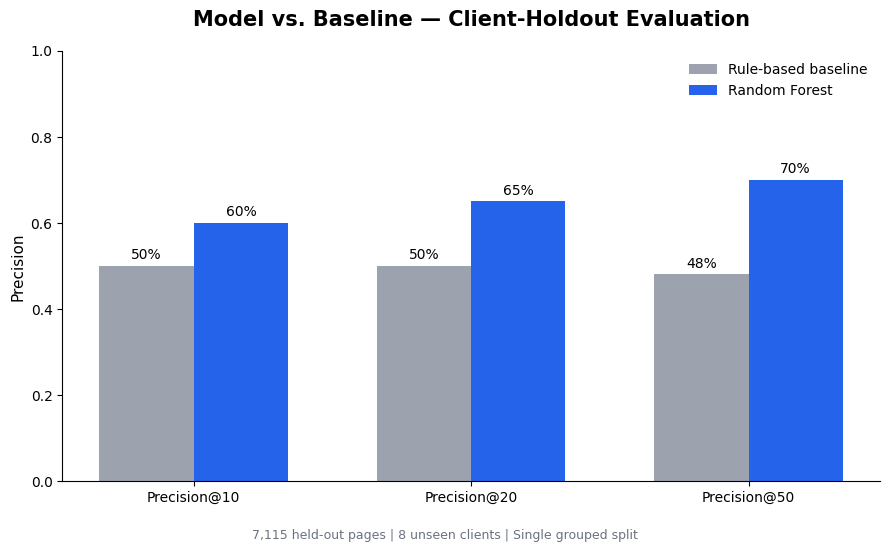

Figure saved: /content/flyrank-ml-internship/work/figures/capstone_model_comparison.png
Metrics saved: /content/flyrank-ml-internship/work/outputs/capstone_metrics.json
Precision@50 improvement: +22%


In [4]:

import matplotlib.pyplot as plt
from pathlib import Path
import json
import numpy as np

# Create output directories
figures_dir = repo / "work" / "figures"
outputs_dir = repo / "work" / "outputs"

figures_dir.mkdir(parents=True, exist_ok=True)
outputs_dir.mkdir(parents=True, exist_ok=True)

# Use the actual results calculated in Section 3
metrics = ["Precision@10", "Precision@20", "Precision@50"]

baseline_values = comparison.loc[
    comparison["Method"] == "Rule-based baseline", metrics
].iloc[0].to_numpy(dtype=float)

rf_values = comparison.loc[
    comparison["Method"] == "Random Forest", metrics
].iloc[0].to_numpy(dtype=float)

# Create comparison chart
x = np.arange(len(metrics))
width = 0.34

fig, ax = plt.subplots(figsize=(9, 5.5))

bars_baseline = ax.bar(
    x - width / 2,
    baseline_values,
    width,
    label="Rule-based baseline",
    color="#9CA3AF"
)

bars_rf = ax.bar(
    x + width / 2,
    rf_values,
    width,
    label="Random Forest",
    color="#2563EB"
)

ax.set_title(
    "Model vs. Baseline — Client-Holdout Evaluation",
    fontsize=15,
    weight="bold",
    pad=18
)

ax.set_ylabel("Precision", fontsize=11)
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1.0)
ax.legend(frameon=False)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

for bars in [bars_baseline, bars_rf]:
    for bar in bars:
        height = bar.get_height()
        ax.annotate(
            f"{height:.0%}",
            xy=(bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            fontsize=10
        )

fig.text(
    0.5, 0.01,
    "7,115 held-out pages | 8 unseen clients | Single grouped split",
    ha="center",
    fontsize=9,
    color="#6B7280"
)

plt.tight_layout(rect=[0, 0.045, 1, 1])

# Save figure
figure_path = figures_dir / "capstone_model_comparison.png"
fig.savefig(
    figure_path,
    dpi=220,
    bbox_inches="tight"
)

plt.show()

# Save metrics as reproducibility evidence
metrics_export = {
    "dataset": "FlyRank anonymized starter sample",
    "total_pages": int(len(df)),
    "train_pages": int(len(train)),
    "test_pages": int(len(test)),
    "train_clients": int(train["client_id"].nunique()),
    "test_clients": int(test["client_id"].nunique()),
    "validation": "GroupShuffleSplit by client_id",
    "random_state": 42,
    "model": "Random Forest",
    "primary_metric": "Precision@50",
    "comparison": {
        row["Method"]: {
            metric: float(row[metric])
            for metric in metrics
        }
        for _, row in comparison.iterrows()
    }
}

metrics_path = outputs_dir / "capstone_metrics.json"

with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(metrics_export, f, indent=2)

print("Figure saved:", figure_path)
print("Metrics saved:", metrics_path)
print("Precision@50 improvement:",
      f"{rf_values[2] - baseline_values[2]:+.0%}")


## 5. Limitations and Honest Interpretation

### 5.1 Dataset Representativeness

The main experiment uses 30,000 anonymized page-level observations from 32 clients. Although FlyRank provides a larger production-derived data warehouse, the reported model comparison was conducted only on this starter sample.

The findings may not generalize to all industries, languages, search environments, or content portfolios.

### 5.2 Validation Limitations

The primary evaluation used one client-grouped train/test split containing 24 training clients and eight held-out clients.

The Random Forest achieved Precision@50 of 0.70, compared with 0.48 for the baseline.

However, this is a single evaluation rather than repeated cross-validation. Model performance could differ on other client groups.

A separate validation audit observed Precision@50 of 0.88 under random page splitting, compared with 0.70 under client-holdout validation. The difference illustrates sensitivity to evaluation design but does not precisely quantify leakage.

### 5.3 Temporal Leakage Risk

The observed-decline label is derived from search-performance trends.

Although directly target-derived columns were excluded and preprocessing was fitted using training data only, the starter snapshot does not fully establish whether all input features preceded the target observation period.

Therefore, this study does not demonstrate leakage-free future forecasting.

### 5.4 Missing Data

The `word_count` feature was missing for 25.66% of observations.

Median imputation was used within the modeling pipeline, with imputation values learned exclusively from training data.

This allows the model to process missing values but does not recover the underlying information or eliminate potential missingness bias.

### 5.5 Model Errors and Calibration

Among the Random Forest's 50 highest-ranked recommendations, 15 pages were not labeled as declining.

Some false positives received scores exceeding 0.90, demonstrating that high model scores do not guarantee correctness.

The scores have not been independently calibrated and should not be interpreted as verified probabilities of future decline.

### 5.6 No Causal Evidence of Editorial Impact

The model classifies observed decline patterns. It does not estimate the effect of refreshing, rewriting, or optimizing individual pages.

No controlled editorial intervention experiment was conducted.

Consequently, the reported results do not establish improvements in organic traffic, search rankings, conversions, or revenue.

### 5.7 Deployment and Operational Limitations

This research is a non-production prototype.

The exported action queue is intended for human editorial investigation. It has not been validated as an automated production decision-making system.

All editorial recommendations require human review, data verification, and approval.

### 5.8 Future Work

Further research should:

1. Reconstruct time-aligned features and future outcome labels.
2. Evaluate performance using repeated client-grouped and forward-in-time validation.
3. Investigate the impact of missing features and client-specific differences.
4. Calibrate model scores and analyze ranking stability.
5. Collect human-review feedback on recommended pages.
6. Conduct controlled intervention studies to measure whether editorial actions produce incremental value.

### Summary

The evidence supports a limited conclusion: on one held-out client evaluation, the Random Forest ranked pages labeled as declining more effectively than the specified rule-based baseline.

The findings justify further investigation of machine-learning-assisted content prioritization, not claims of proven business improvement or production readiness.

## 6. Ranked Recommendations and Content Action Playbook

### 6.1 Purpose

This study proposes a human-reviewed content prioritization framework that translates model rankings into practical editorial investigations.

The Random Forest assigns scores based on patterns associated with observed search-performance decline. These scores establish review priority, not verified future decline probabilities or expected traffic improvements.

The ranked queue contains **7,115 held-out pages**, corresponding to eight previously unseen clients.

### 6.2 Recommended Actions

Five reason codes translate page characteristics into proposed review actions.

| Reason code | Pages | Recommended investigation |
|---|---:|---|
| `CHECK_DATA` | 2,684 | Verify measurement coverage and search demand before proceeding |
| `REVIEW_DECLINE` | 2,027 | Investigate observed search-performance signals |
| `REVIEW_CTR` | 895 | Review search snippets, titles, and query intent |
| `REVIEW_POSITION` | 835 | Examine topical relevance, internal links, and content coverage |
| `REVIEW_FRESHNESS` | 674 | Inspect mature content for outdated information |
| **Total** | **7,115** | |

These counts describe the exported research queue. The reason codes are transparent heuristics rather than independently validated diagnoses.

### 6.3 Ranking Method

Pages are ordered by their Random Forest decline scores.

After ranking, each page receives a descriptive reason code based on its search visibility, search position, CTR, content age, and update recency.

A higher model score indicates greater ranking priority within this research model. It does not establish that a particular intervention will be effective.

### 6.4 Content Decay and Refresh Insight

FlyRank's March 2026 research observed that recently refreshed mature pages were associated with stronger performance indicators than certain stale-page groups.

This motivates investigating freshness as a possible editorial review signal.

However, the findings are observational. Differences in existing content quality, search demand, and editorial selection may explain part of the measured relationship.

The playbook therefore recommends inspecting older content rather than automatically refreshing it.

### 6.5 Human Review Workflow

Each recommendation follows a proposed review process:

1. Verify the underlying search-performance measurements.
2. Inspect the page's content, audience, and search intent.
3. Confirm whether a specific editorial issue exists.
4. Estimate review effort and potential business relevance.
5. Select an appropriate action or reject the recommendation.
6. Obtain editorial approval before making changes.
7. Monitor subsequent performance after any approved intervention.

All generated recommendations include:

- `requires_human_review = True`
- `approval_status = "PENDING_REVIEW"`

### 6.6 Cost and Value Considerations

Editorial review capacity is limited, so model-based prioritization should be considered alongside:

- Expected investigation and editing effort.
- Existing search visibility.
- Business relevance of the page.
- Confidence in the human-confirmed diagnosis.
- Opportunity cost of reviewing other pages.

The model does not estimate revenue, financial return, or causal traffic uplift.

Cost/value assessment remains a human decision until reliable intervention-outcome data becomes available.

### 6.7 Prohibited Automated Actions

The research prototype must not automatically:

- Rewrite or publish website content.
- Delete pages or modify indexing directives.
- Change canonical URLs or important site navigation.
- Generate unverified factual claims or citations.
- Make medical, legal, or financial content changes without qualified review.
- Publish keyword-stuffed or otherwise manipulative SEO content.
- Expose confidential information across clients.
- Guarantee ranking, traffic, or revenue improvements.

### 6.8 Monitoring and Retraining

A future implementation should periodically monitor ranking quality, missing data, input-distribution changes, and human-review outcomes.

Proposed investigation triggers include Precision@50 falling below 0.60, significant input drift, or persistent increases in rejected recommendations.

These thresholds are illustrative and have not been validated as production operating limits.

Retraining should be considered only after investigating the underlying issue and obtaining sufficiently reliable new data.

### 6.9 Recommendation Summary

The observed results support using the model as an experimental tool for prioritizing editorial investigation.

They do not support autonomous SEO optimization.

The recommended approach is to combine model rankings, interpretable reason codes, editorial expertise, and post-intervention measurement within a transparent human-review workflow.

## 7. Research Artifacts and Reproducibility

### 7.1 Reproducibility

The research code, notebooks, and supporting artifacts are available in the public GitHub repository:

**Repository:** [FlyRank ML Internship — Borjan Ladinski](https://github.com/Ladinski/flyrank-ml-internship)

The analysis was developed in Python using pandas, NumPy, scikit-learn, and Matplotlib.

The main experiment uses `GroupShuffleSplit` with `random_state=42` and a Random Forest containing 200 trees with `min_samples_leaf=5`.

The experiment can be reproduced using the anonymized starter dataset, subject to the data access requirements of the repository.

### 7.2 Supporting Notebooks

| Notebook | Research contribution |
|---|---|
| [Week 1 — Research Question](https://github.com/Ladinski/flyrank-ml-internship/blob/main/work/notebooks/w01_research_question.ipynb) | Business problem and research motivation |
| [Week 2 — ML Task Framing](https://github.com/Ladinski/flyrank-ml-internship/blob/main/work/notebooks/w02_ml_task_framing.ipynb) | Target definition, features, and evaluation metrics |
| [Week 3 — Data Contract](https://github.com/Ladinski/flyrank-ml-internship/blob/main/work/notebooks/w03_data_contract.ipynb) | Warehouse exploration and data validation |
| [Week 4 — Baseline Score](https://github.com/Ladinski/flyrank-ml-internship/blob/main/work/notebooks/w04_baseline_score.ipynb) | Transparent rule-based prioritization |
| [Week 5 — Model](https://github.com/Ladinski/flyrank-ml-internship/blob/main/work/notebooks/w05_model.ipynb) | Random Forest training and baseline comparison |
| [Week 6 — Validation Audit](https://github.com/Ladinski/flyrank-ml-internship/blob/main/work/notebooks/w06_validation_audit.ipynb) | Grouped validation, leakage audit, and failure analysis |
| [Week 7 — Action Playbook](https://github.com/Ladinski/flyrank-ml-internship/blob/main/work/notebooks/w07_action_playbook.ipynb) | Human-reviewed recommendations and reason codes |
| [Capstone Notebook](https://github.com/Ladinski/flyrank-ml-internship/blob/main/work/notebooks/capstone.ipynb) | Integrated research paper and reproducible results |

### 7.3 Publication Figures

**Figure 1 — Model versus Baseline**

`work/figures/capstone_model_comparison.png`

This figure presents Precision@10, Precision@20, and Precision@50 for the Random Forest and rule-based baseline using the same client-holdout evaluation set.

**Figure 2 — Action Reason Code Distribution**

`work/figures/w07_reason_code_distribution.png`

This figure summarizes the five human-review categories assigned to the 7,115-page ranked queue.

### 7.4 Supporting Metrics

The research exports machine-readable evaluation summaries:

- `work/outputs/capstone_metrics.json`
- `work/outputs/w07_action_metrics.json`

The ranked page queue is generated as:

`work/outputs/w07_ranked_action_queue.csv`

The queue CSV is intentionally excluded from version control under the repository's data-safety policy and can be regenerated by executing the Week 7 notebook.

### 7.5 Reproduction Procedure

1. Clone the public GitHub repository.
2. Install the notebook's Python dependencies.
3. Obtain the authorized anonymized starter dataset.
4. Open and execute `work/notebooks/capstone.ipynb`.
5. Verify the client-grouped split and model-versus-baseline metrics.
6. Execute `work/notebooks/w07_action_playbook.ipynb` to regenerate the ranked queue and reason-code distribution.
7. Compare the resulting outputs with the committed metrics and figures.

### 7.6 Acknowledgments and Data Credit

**Built on the [FlyRank ML Internship dataset](https://flyrank.ai).**

I acknowledge FlyRank for providing the internship research framework, anonymized experimental data, and opportunities to investigate real-world search-performance challenges.

The experimental design, interpretation, and conclusions presented in this capstone are those of the author and should not be interpreted as official FlyRank product-performance claims.

### 7.7 Research Availability

The published research page presents aggregate results, methodology, figures, limitations, and implementation recommendations.

The accompanying GitHub repository provides the technical evidence and reproducibility materials supporting these claims.

In [5]:

import json
from pathlib import Path

# Research artifact locations
repo = Path("/content/flyrank-ml-internship")

required_artifacts = {
    "Model comparison figure":
        repo / "work/figures/capstone_model_comparison.png",
    "Action playbook figure":
        repo / "work/figures/w07_reason_code_distribution.png",
    "Capstone metrics":
        repo / "work/outputs/capstone_metrics.json",
    "Week 7 metrics":
        repo / "work/outputs/w07_action_metrics.json"
}

print("RESEARCH ARTIFACT VERIFICATION")
print("-" * 45)

missing = []

for name, path in required_artifacts.items():
    exists = path.is_file()
    print(f"{name}: {'FOUND' if exists else 'MISSING'}")

    if not exists:
        missing.append(name)

# Verify capstone evaluation metrics
metrics_path = required_artifacts["Capstone metrics"]

if metrics_path.exists():
    with open(metrics_path, encoding="utf-8") as f:
        metrics_data = json.load(f)

    baseline_p50 = metrics_data["comparison"][
        "Rule-based baseline"
    ]["Precision@50"]

    model_p50 = metrics_data["comparison"][
        "Random Forest"
    ]["Precision@50"]

    print("\nVERIFIED MODEL RESULTS")
    print("Baseline Precision@50:", baseline_p50)
    print("Random Forest Precision@50:", model_p50)
    print("Improvement:", round(model_p50 - baseline_p50, 3))

    assert abs(baseline_p50 - 0.48) < 1e-9
    assert abs(model_p50 - 0.70) < 1e-9

# Verify no client identifiers are exported in Week 7 queue
queue_path = repo / "work/outputs/w07_ranked_action_queue.csv"

if queue_path.exists():
    import pandas as pd

    queue_columns = pd.read_csv(queue_path, nrows=0).columns
    prohibited_columns = {
        "client_id", "client_name", "url",
        "page_url", "query", "search_query"
    }

    assert not prohibited_columns.intersection(queue_columns)
    print("\nQueue column safety check passed.")
else:
    print("\nQueue CSV not found in this runtime.")
    print("It can be regenerated by running Week 7.")

print("\nMissing artifacts:", len(missing))

if missing:
    print("Some artifacts must be added before publication.")
else:
    print("All required research artifacts found.")


RESEARCH ARTIFACT VERIFICATION
---------------------------------------------
Model comparison figure: FOUND
Action playbook figure: MISSING
Capstone metrics: FOUND
Week 7 metrics: MISSING

VERIFIED MODEL RESULTS
Baseline Precision@50: 0.48
Random Forest Precision@50: 0.7
Improvement: 0.22

Queue CSV not found in this runtime.
It can be regenerated by running Week 7.

Missing artifacts: 2
Some artifacts must be added before publication.


In [6]:

from pathlib import Path
import subprocess

repo = Path("/content/flyrank-ml-internship")

# Fetch latest committed files without overwriting notebook work
subprocess.run(
    ["git", "-C", str(repo), "fetch", "origin", "main"],
    check=True
)

missing_files = [
    "work/figures/w07_reason_code_distribution.png",
    "work/outputs/w07_action_metrics.json"
]

for relative_path in missing_files:
    destination = repo / relative_path

    if destination.exists():
        print("ALREADY PRESENT:", relative_path)
        continue

    result = subprocess.run(
        [
            "git", "-C", str(repo),
            "show", f"origin/main:{relative_path}"
        ],
        capture_output=True
    )

    if result.returncode == 0:
        destination.parent.mkdir(parents=True, exist_ok=True)
        destination.write_bytes(result.stdout)
        print("RESTORED:", relative_path)
    else:
        print("NOT COMMITTED:", relative_path)

print("\nVerification:")
for relative_path in missing_files:
    print(relative_path, (repo / relative_path).exists())


NOT COMMITTED: work/figures/w07_reason_code_distribution.png
NOT COMMITTED: work/outputs/w07_action_metrics.json

Verification:
work/figures/w07_reason_code_distribution.png False
work/outputs/w07_action_metrics.json False


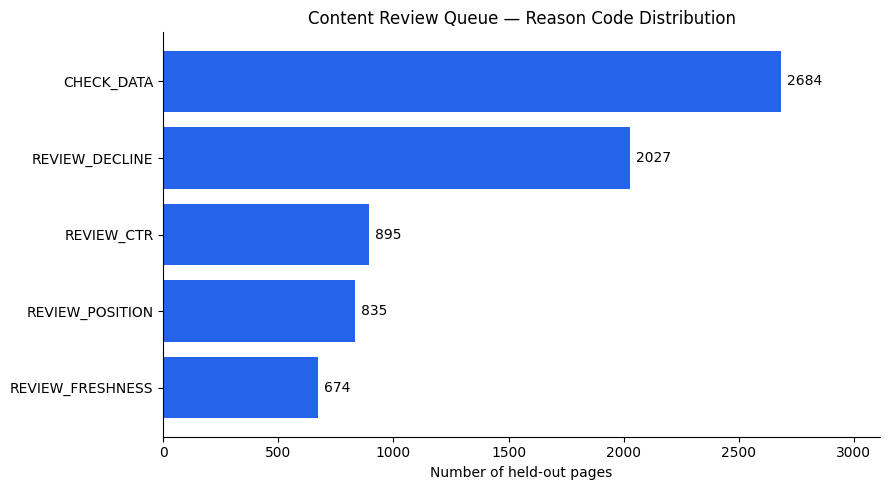

RESTORED: /content/flyrank-ml-internship/work/figures/w07_reason_code_distribution.png
RESTORED: /content/flyrank-ml-internship/work/outputs/w07_action_metrics.json
Total ranked pages: 7115


In [7]:

import json
import matplotlib.pyplot as plt
from pathlib import Path

repo = Path("/content/flyrank-ml-internship")
figures_dir = repo / "work/figures"
outputs_dir = repo / "work/outputs"

figures_dir.mkdir(parents=True, exist_ok=True)
outputs_dir.mkdir(parents=True, exist_ok=True)

# Week 7 verified reason-code counts
reason_counts = {
    "CHECK_DATA": 2684,
    "REVIEW_DECLINE": 2027,
    "REVIEW_CTR": 895,
    "REVIEW_POSITION": 835,
    "REVIEW_FRESHNESS": 674
}

assert sum(reason_counts.values()) == 7115

# Recreate publication figure
labels = list(reason_counts.keys())[::-1]
values = [reason_counts[k] for k in labels]

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(labels, values, color="#2563EB")

ax.set_title("Content Review Queue — Reason Code Distribution")
ax.set_xlabel("Number of held-out pages")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

for bar in bars:
    ax.text(
        bar.get_width() + 25,
        bar.get_y() + bar.get_height() / 2,
        str(int(bar.get_width())),
        va="center"
    )

ax.set_xlim(0, max(values) * 1.16)
plt.tight_layout()

figure_path = figures_dir / "w07_reason_code_distribution.png"
fig.savefig(figure_path, dpi=220, bbox_inches="tight")
plt.show()

# Restore a metrics summary from previously verified results
metrics = {
    "project": "Refresh / Content Opportunity Scoring",
    "source": "Week 7 verified notebook results",
    "validation": "Client-holdout GroupShuffleSplit",
    "random_state": 42,
    "training_pages": 22885,
    "test_pages": 7115,
    "ranked_pages": 7115,
    "precision_at_50": 0.70,
    "top_50_correct": 35,
    "top_50_false_positives": 15,
    "reason_code_counts": reason_counts,
    "limitations": [
        "Observed decline classification, not future decline forecasting",
        "Single client-holdout split",
        "Uncalibrated model scores",
        "Temporal feature availability not fully verified",
        "Human editorial approval required"
    ]
}

metrics_path = outputs_dir / "w07_action_metrics.json"
metrics_path.write_text(json.dumps(metrics, indent=2), encoding="utf-8")

print("RESTORED:", figure_path)
print("RESTORED:", metrics_path)
print("Total ranked pages:", sum(reason_counts.values()))


## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.
- [ ] My deployed paper has **all 9 sections** — including the **Abstract** at the top and **Acknowledgments & data credit** (the https://flyrank.ai link) at the bottom.
- [ ] **ML-12 done in this notebook's closing cells:** 5-minute demo outline + a social-post cut + a 3-sentence employer-facing summary.
